# 03 · Extractive answers and the guardrail (Member 4: chatbot)

**Change of plan (Phase 6):** there is no trained text generator. Answers are **extractive**: the chatbot copies
the best 1–3 sentences (or the table) of the best passage, so it can never invent a number. This notebook
chooses, **on the validation split only**:
1. the passage ranking per language: our fine-tuned retriever alone (`dense`) or fused with BM25 (`rrf`)
2. the refusal threshold on the retriever score (together with the intent model's own threshold)
3. how many sentences to copy and how close their scores must be to the best one

and then reports once on the test split, against a simple extractive baseline (the first two sentences of the top
passage). Saves `../artifacts/answer/config.json`, `metrics.json` and `model_card.md`; the chat API loads that
config.

Unlike notebooks 00–02 this one **uses the project code** (`member4_chatbot`), because it tunes and tests the exact
answer code the API runs. It still reads its questions only from the CSV files in `data/`.

**Data warning:** all questions are AI-drafted, template-generated or machine-translated and not human-checked
(see DATASET.md). The human-checked test is notebook 04.

In [1]:
SEED = 20261018
import sys
from pathlib import Path
HERE = Path.cwd()
DATA = HERE / "data"
sys.path.insert(0, str(HERE.parent))           # backend/member4-chatbot, for member4_chatbot
ARTIFACTS = HERE.parent / "artifacts"
OUT = ARTIFACTS / "answer"
import json, re, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from member4_chatbot import models
from member4_chatbot.chat.extractive import extract, split_units, unsupported_numbers
from member4_chatbot.chat.retrieval import PassageRanker
from sklearn.metrics import f1_score, precision_recall_fscore_support

In [2]:
passages = pd.read_csv(DATA / "passages.csv", keep_default_na=False)
qa = pd.read_csv(DATA / "qa_pairs.csv", keep_default_na=False)
intents = pd.read_csv(DATA / "intents.csv", keep_default_na=False)
qa["gold"] = [{r.passage_id, *filter(None, r.also_correct.split(";"))} for r in qa.itertuples()]
P = passages.set_index("id")
_, collection = models._retriever()
ranker = PassageRanker.from_chroma(passages, collection)
val, test = (qa[qa.split == s].reset_index(drop=True) for s in ("val", "test"))
oos_val, oos_test = (intents[(intents.split == s) & (intents.intent == "out_of_scope")].reset_index(drop=True) for s in ("val", "test"))
print(f"in-scope questions with a passage: val {len(val)}, test {len(test)}; out-of-scope: val {len(oos_val)}, test {len(oos_test)}")

The tokenizer you are loading from 'E:\soilmind\backend\member4-chatbot\artifacts\retriever\model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


in-scope questions with a passage: val 251, test 228; out-of-scope: val 48, test 50


In [3]:
def emb(texts): return models.embed(list(texts))
Q = {s: emb(d.question) for s, d in (("val", val), ("test", test))}
QO = {s: emb(d.text) for s, d in (("val", oos_val), ("test", oos_test))}
_cache = {}
def encode_cached(texts):
    missing = [t for t in dict.fromkeys(texts) if t not in _cache]
    if missing:
        for t, e in zip(missing, emb(missing)): _cache[t] = e
    return np.vstack([_cache[t] for t in texts])
print("question embeddings ready")

question embeddings ready


## 1. Passage ranking per language: dense vs dense + BM25 (validation hit@3)

In [4]:
def hit3(frame, Qe, mode):
    return np.array([any(h.passage_id in g for h in ranker.rank(q, txt, mode, 3)) for q, txt, g in zip(Qe, frame.question, frame.gold)])
rows, MODE = [], {}
for lang in ("en", "si"):
    m = (val.lang == lang).to_numpy()
    scores = {mode: hit3(val[m], Q["val"][m], mode).mean() for mode in ("dense", "rrf")}
    MODE[lang] = max(scores, key=lambda k: (scores[k], k == "dense"))   # tie -> our model alone
    rows.append({"lang": lang, **{f"val hit@3 {k}": round(v, 4) for k, v in scores.items()}, "chosen": MODE[lang]})
pd.DataFrame(rows)

,lang,val hit@3 dense,val hit@3 rrf,chosen
0,en,0.8258,0.8939,rrf
1,si,0.7311,0.6723,dense


## 2. Refusal threshold (validation)
A question is refused if the intent model says `out_of_scope` (its own threshold, chosen in notebook 01) **or** the
best retriever score is below τ. τ is chosen to maximise macro-F1 of the refuse / answer decision on validation:
in-scope questions that have an answer passage should be answered, out-of-scope questions refused.

The tokenizer you are loading from 'E:\soilmind\backend\member4-chatbot\artifacts\intent\model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


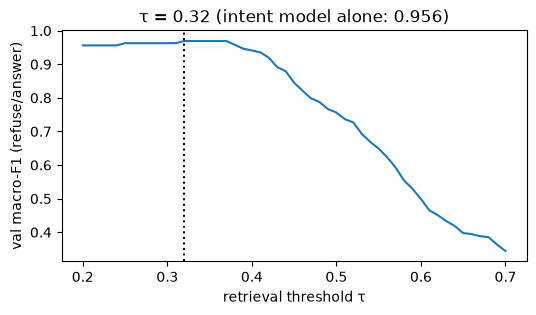

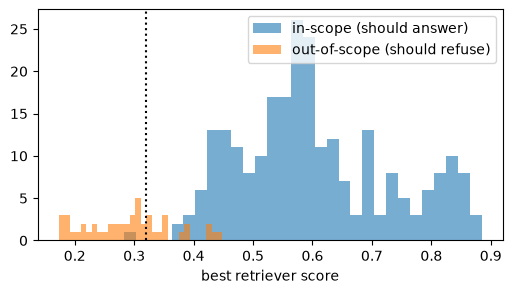

In [5]:
def intent_oos(texts):
    return np.array([models.predict_intent(t).intent == "out_of_scope" for t in texts])
def best_dense(Qe): return np.array([ranker.best_dense(q) for q in Qe])
V = pd.DataFrame({"refuse": np.r_[np.zeros(len(val)), np.ones(len(oos_val))].astype(bool),
                  "intent_oos": np.r_[intent_oos(val.question), intent_oos(oos_val.text)],
                  "score": np.r_[best_dense(Q["val"]), best_dense(QO["val"])],
                  "lang": np.r_[val.lang, oos_val.lang]})
grid = np.round(np.arange(0.20, 0.701, 0.01), 2)
f1s = [f1_score(V.refuse, V.intent_oos | (V.score < t), average="macro") for t in grid]
TAU_R = float(grid[int(np.argmax(f1s))])
INTENT_ONLY_VAL_F1 = f1_score(V.refuse, V.intent_oos, average="macro")
plt.figure(figsize=(6, 3)); plt.plot(grid, f1s); plt.axvline(TAU_R, c="k", ls=":"); plt.xlabel("retrieval threshold τ"); plt.ylabel("val macro-F1 (refuse/answer)")
plt.title(f"τ = {TAU_R} (intent model alone: {INTENT_ONLY_VAL_F1:.3f})"); plt.show()
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(V.score[~V.refuse], bins=30, alpha=.6, label="in-scope (should answer)"); ax.hist(V.score[V.refuse], bins=30, alpha=.6, label="out-of-scope (should refuse)")
ax.axvline(TAU_R, c="k", ls=":"); ax.set_xlabel("best retriever score"); ax.legend(); plt.show()

## 3. Sentence settings (validation)
The answer passage is the top-ranked one (in the question's language if it scores within 0.05 of the top). Key facts
of a question = the numbers and variety codes in its expected answer that also appear in the expected passage.
**Key-fact recall** = share of those that appear in our answer; **ROUGE-L recall** = word overlap with the expected
answer. Settings are chosen on validation key-fact recall (ties → fewer sentences).

In [6]:
FACT = re.compile(r"(?:Bg|At|Bw|Ld|H)\s?\d+(?:[-/]\d+)?|\d+(?:\.\d+)?")
def facts(answer, passage_ids):
    ptxt = " ".join(P.loc[p, "text"] for p in passage_ids if p in P.index)
    return {f for f in FACT.findall(answer) if f in ptxt}
def lcs(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b):
            cur = dp[j + 1]; dp[j + 1] = prev + 1 if x == y else max(dp[j + 1], dp[j]); prev = cur
    return dp[-1]
def rouge_l_recall(pred, ref):
    p, r = pred.lower().split(), ref.lower().split()
    return lcs(p, r) / len(r) if r else 0.0

def answer_one(q_emb, question, lang, max_sentences, margin, delta=0.05):
    hits = ranker.rank(q_emb, question, MODE[lang], 5)
    lead = hits[0].score
    chosen = next((h for h in hits if h.score >= lead - delta and h.lang == lang), hits[0])
    row = P.loc[chosen.passage_id]
    ex = extract(chosen.passage_id, row["text"], row["title"], q_emb, encode_cached, max_sentences=max_sentences, margin=margin)
    return chosen.passage_id, "\n".join(ex.lines)

def baseline_one(q_emb, question, lang):
    hits = ranker.rank(q_emb, question, MODE[lang], 5)
    row = P.loc[hits[0].passage_id]
    units = split_units(row["text"], row["title"])
    return hits[0].passage_id, "\n".join(u.text for u in units[:2])

def score_answers(frame, preds):
    out = []
    for r, (pid, ans) in zip(frame.itertuples(), preds):
        f = facts(r.answer, r.gold)
        out.append({"lang": r.lang, "passage_ok": pid in r.gold, "facts": len(f),
                    "fact_recall": (sum(x in ans for x in f) / len(f)) if f else np.nan,
                    "rouge_l_recall": rouge_l_recall(ans, r.answer), "words": len(ans.split()),
                    "unsupported_numbers": len(unsupported_numbers(ans, P.loc[pid, "text"]))})
    return pd.DataFrame(out)

results = []
for ms, mg in itertools.product((1, 2, 3), (0.03, 0.05, 0.08, 0.12)):
    preds = [answer_one(q, t, l, ms, mg) for q, t, l in zip(Q["val"], val.question, val.lang)]
    s = score_answers(val, preds)
    results.append({"max_sentences": ms, "margin": mg, "val_fact_recall": round(s.fact_recall.mean(), 4),
                    "val_rouge_l": round(s.rouge_l_recall.mean(), 4), "words": round(s.words.mean(), 1)})
grid_df = pd.DataFrame(results).sort_values(["val_fact_recall", "max_sentences", "margin"], ascending=[False, True, True])
BEST = grid_df.iloc[0]
MAX_SENT, MARGIN = int(BEST.max_sentences), float(BEST.margin)
print(f"chosen: max_sentences = {MAX_SENT}, margin = {MARGIN}")
grid_df.head(8)

chosen: max_sentences = 2, margin = 0.12


,max_sentences,margin,val_fact_recall,val_rouge_l,words
7,2,0.12,0.7478,0.2411,85.6
11,3,0.12,0.7478,0.2554,94.0
6,2,0.08,0.7319,0.2339,82.3
10,3,0.08,0.7319,0.2471,88.3
5,2,0.05,0.7125,0.2287,79.1
9,3,0.05,0.7125,0.2360,82.4
4,2,0.03,0.6927,0.2215,75.0
8,3,0.03,0.6927,0.2288,76.6


## 4. Test split (used once): our extractive answers vs the baseline

In [7]:
t0 = time.perf_counter()
ours = [answer_one(q, t, l, MAX_SENT, MARGIN) for q, t, l in zip(Q["test"], test.question, test.lang)]
ANSWER_MS = (time.perf_counter() - t0) / len(test) * 1000
base = [baseline_one(q, t, l) for q, t, l in zip(Q["test"], test.question, test.lang)]
S_ours, S_base = score_answers(test, ours), score_answers(test, base)
def summary(S):
    g = {"all": S, "en": S[S.lang == "en"], "si": S[S.lang == "si"]}
    return {k: {"n": len(v), "passage_hit": round(v.passage_ok.mean(), 4), "fact_recall": round(v.fact_recall.mean(), 4),
                "questions_with_facts": int(v.facts.gt(0).sum()), "rouge_l_recall": round(v.rouge_l_recall.mean(), 4),
                "hallucinated_number_rate": round(float((v.unsupported_numbers > 0).mean()), 4), "mean_words": round(v.words.mean(), 1)} for k, v in g.items()}
SUM = {"extractive": summary(S_ours), "baseline_first_2_sentences": summary(S_base)}
pd.DataFrame({(m, l): v for m, d in SUM.items() for l, v in d.items()}).T

n  passage_hit  fact_recall  \
extractive                 all  228.0       0.5395       0.6604   
                           en   114.0       0.6228       0.6548   
                           si   114.0       0.4561       0.6657   
baseline_first_2_sentences all  228.0       0.5263       0.2519   
                           en   114.0       0.6228       0.3016   
                           si   114.0       0.4298       0.2045   

                                questions_with_facts  rouge_l_recall  \
extractive                 all                 172.0          0.2041   
                           en                   84.0          0.2318   
                           si                   88.0          0.1765   
baseline_first_2_sentences all                 172.0          0.1103   
                           en                   84.0          0.1518   
                           si                   88.0          0.0687   

                                hallucinated_number_rate  mean_words  
extractive                 all                       0.0        84.7  
                           en                        0.0        76.5  
                           si                        0.0        92.9  
baseline_first_2_sentences all                       0.0        42.4  
                           en                        0.0        46.2  
                           si                        0.0        38.7

In [8]:
T = pd.DataFrame({"refuse": np.r_[np.zeros(len(test)), np.ones(len(oos_test))].astype(bool),
                  "intent_oos": np.r_[intent_oos(test.question), intent_oos(oos_test.text)],
                  "score": np.r_[best_dense(Q["test"]), best_dense(QO["test"])], "lang": np.r_[test.lang, oos_test.lang]})
def refusal(frame, use_retrieval=True):
    pred = frame.intent_oos | (frame.score < TAU_R) if use_retrieval else frame.intent_oos
    p, r, f, _ = precision_recall_fscore_support(frame.refuse, pred, average="binary", zero_division=0)
    return {"precision": round(p, 4), "recall": round(r, 4), "f1": round(f, 4), "wrongly_refused_in_scope": int((pred & ~frame.refuse).sum())}
REFUSAL = {"intent_only": refusal(T, False), "intent_plus_retrieval_threshold": refusal(T, True),
           **{f"intent_plus_threshold_{l}": refusal(T[T.lang == l], True) for l in ("en", "si")}}
pd.DataFrame(REFUSAL).T

,precision,recall,f1,wrongly_refused_in_scope
intent_only,0.8409,0.7400,0.7872,7.0
intent_plus_retrieval_threshold,0.8261,0.7600,0.7917,8.0
intent_plus_threshold_en,0.9048,0.7308,0.8085,2.0
intent_plus_threshold_si,0.7600,0.7917,0.7755,6.0


In [9]:
ex = test.assign(ours=[a for _, a in ours]).sample(4, random_state=SEED)
for r in ex.itertuples():
    print(f"[{r.lang}] Q: {r.question}\n   expected: {r.answer}\n   ours: {r.ours[:300]}\n")

[si] Q: Bg 360 කොළ පාළුවට ඔරොත්තු දෙනවද?
   expected: Bg 360 කොළ පාළුව සඳහා: අවදානමට ලක්විය හැකි.
   ours: පළිබෝධ සහ රෝග සඳහා ප්‍රතිරෝධය
පළිබෝධ සහ රෝග සඳහා ප්‍රතිරෝධය

[si] Q: ප්‍රාථමික ගොවිතැන් කරන්නේ ඇයි?
   expected: එය මුල් කලාපය ගැඹුරු කරන අතර පෘථිවියේ කාබනික ද්‍රව්‍ය වර්ධනය කිරීම සඳහා කෙසෙල් සහ බෝග අවශේෂ ඇතුළත් කරයි.
   ours: Have they ever cultivated land to earn their livings?
But we have people from all sectors, including Buddhist monks (I am a Buddhist) promoting sustainable green agriculture with no strategies defined for successful implementation.

[si] Q: කුමන වර්ගවලට පිපිරීම් වලට ලක්විය හැකිද?
   expected: Bg 358, Bg 357, Bg 360, Bw 367, At 373 සහ Bg 94/1 පිපිරීමට ලක්විය හැකි බව ලැයිස්තුගත කර ඇත.
   ours: If the disease spread fast, following fungicides could be applied
Tebuconazole 250g/l EC – dissolve 10 ml in 16 l of water (8-10 tanks per acre)
Isoprothiolane 400g/l EC – dissolve 20 ml in 16 l of water (8-10 tanks per acre)
Carbendazim 50% WP/WG – dissolve 11 g/ 11 ml 

## 5. Save the configuration the chat API uses

In [10]:
OUT.mkdir(parents=True, exist_ok=True)
config = {"retrieval_threshold": TAU_R, "max_sentences": MAX_SENT, "margin": MARGIN, "same_language_delta": 0.05,
          "top_k": 5, "retrieval_mode": MODE, "chosen_on": "validation split", "seed": SEED}
(OUT / "config.json").write_text(json.dumps(config, indent=2))
metrics = {"config": config, "validation_grid": results, "validation_mode_hit3": rows,
           "validation_refusal_macro_f1": {"intent_only": round(INTENT_ONLY_VAL_F1, 4), "with_threshold": round(max(f1s), 4)},
           "test": SUM, "refusal_test": REFUSAL, "answer_ms_per_question_cpu": round(ANSWER_MS, 1),
           "data_warning": "questions are AI-drafted / template / machine-translated, not human-checked"}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
e, b = SUM["extractive"], SUM["baseline_first_2_sentences"]
card = f'''# Model card: SoilMind extractive answer step

**What it does.** Answers a question by copying the best 1-{MAX_SENT} sentences (or the whole short table) of the best
DOA/RRDI passage. No text is generated, so numbers come only from the cited passage. "My field" questions use
bilingual templates filled from Member 2/3 APIs instead.

**Uses our models only:** the fine-tuned retriever (passage ranking and sentence scores) and the intent classifier.
Passage ranking per language (validation hit@3): English `{MODE["en"]}`, Sinhala `{MODE["si"]}`.

**Guardrail.** Refuse and escalate when the intent is `out_of_scope` or the best retriever score is below
**τ = {TAU_R}** (chosen on validation macro-F1 of refuse/answer).

**Training data is NOT human-checked.** All questions here are AI-drafted, template-generated or machine-translated
(DATASET.md). The human-checked evaluation is notebook 04.

**Test results** (AI-drafted questions, test split):

| | Passage hit | Key-fact recall | ROUGE-L recall | Hallucinated-number rate | Mean words |
|---|---|---|---|---|---|
| Extractive (ours), English | {e["en"]["passage_hit"]} | {e["en"]["fact_recall"]} | {e["en"]["rouge_l_recall"]} | {e["en"]["hallucinated_number_rate"]} | {e["en"]["mean_words"]} |
| Extractive (ours), Sinhala | {e["si"]["passage_hit"]} | {e["si"]["fact_recall"]} | {e["si"]["rouge_l_recall"]} | {e["si"]["hallucinated_number_rate"]} | {e["si"]["mean_words"]} |
| Baseline (first 2 sentences), English | {b["en"]["passage_hit"]} | {b["en"]["fact_recall"]} | {b["en"]["rouge_l_recall"]} | {b["en"]["hallucinated_number_rate"]} | {b["en"]["mean_words"]} |
| Baseline (first 2 sentences), Sinhala | {b["si"]["passage_hit"]} | {b["si"]["fact_recall"]} | {b["si"]["rouge_l_recall"]} | {b["si"]["hallucinated_number_rate"]} | {b["si"]["mean_words"]} |

Refusal on the test split (intent + τ): precision {REFUSAL["intent_plus_retrieval_threshold"]["precision"]},
recall {REFUSAL["intent_plus_retrieval_threshold"]["recall"]}.

**Limits.** Copied text can be long or awkward (tables); a question answered only in the other language gets the
other-language text with a note; sentence ranking is weaker in Sinhala.
'''
(OUT / "model_card.md").write_text(card, encoding="utf-8")
print(json.dumps(config, indent=2))

{
  "retrieval_threshold": 0.32,
  "max_sentences": 2,
  "margin": 0.12,
  "same_language_delta": 0.05,
  "top_k": 5,
  "retrieval_mode": {
    "en": "rrf",
    "si": "dense"
  },
  "chosen_on": "validation split",
  "seed": 20261018
}
